# Person & head detection with YOLOv8
Fine-tunes YOLOv8-L on a person/head dataset from Roboflow. Runs on Google Colab with a T4 GPU.

Set your Roboflow API key first: `os.environ['ROBOFLOW_API_KEY'] = '...'`

In [ ]:
!nvidia-smi

In [ ]:
!pip install -q ultralytics roboflow
from ultralytics import YOLO
from IPython.display import Image
!yolo mode=checks

## Dataset

In [ ]:
import os
from roboflow import Roboflow

rf = Roboflow(api_key=os.environ['ROBOFLOW_API_KEY'])
project = rf.workspace('saad-salman-xwffp').project('human-persons-kqfbt')
dataset = project.version(1).download('yolov8')

## Train (15 epochs, 640 px)

In [ ]:
!yolo detect mode=train model=yolov8l.pt data={dataset.location}/data.yaml epochs=15 imgsz=640

100% 83.7M/83.7M [00:00<00:00, 228MB/s]
Ultralytics YOLOv8.1.6 🚀 Python-3.10.12 torch-2.1.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: task=detect, mode=train, model=yolov8l.pt, data=/content/persons-1/data.yaml, epochs=15, time=None, patience=50, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False,

## Results

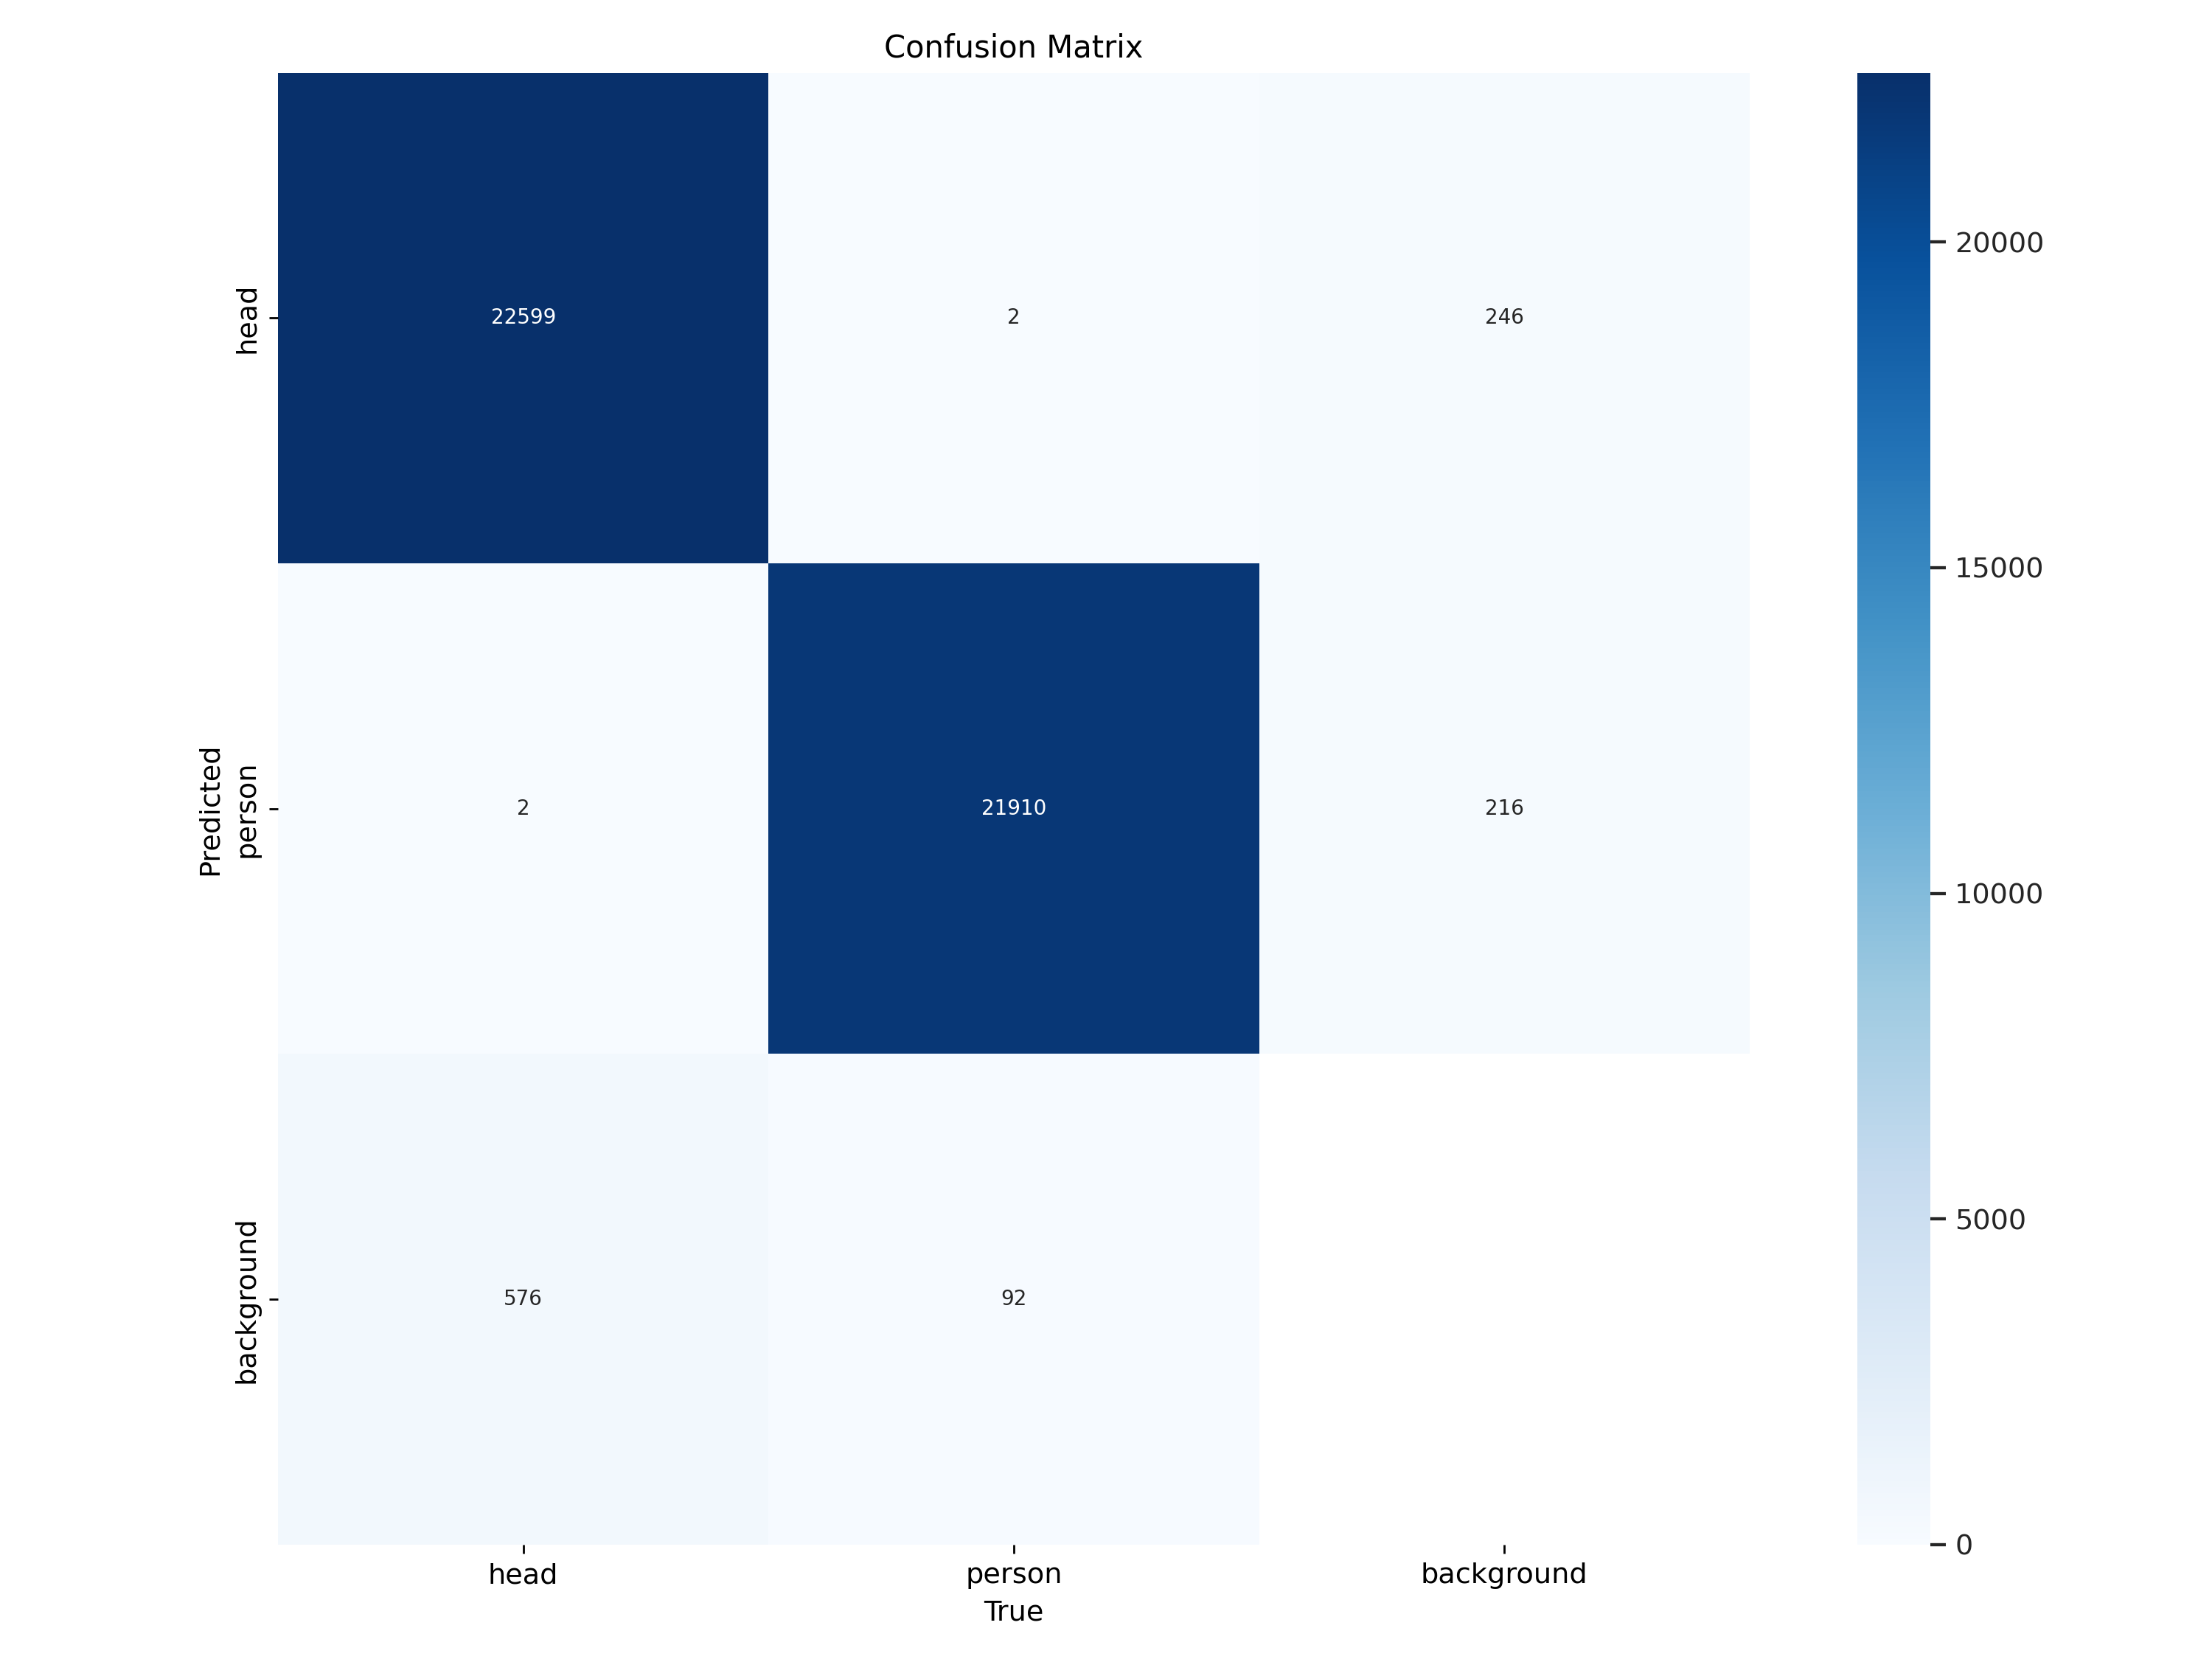

In [ ]:
Image(filename='/content/runs/detect/train/confusion_matrix.png', width=600)

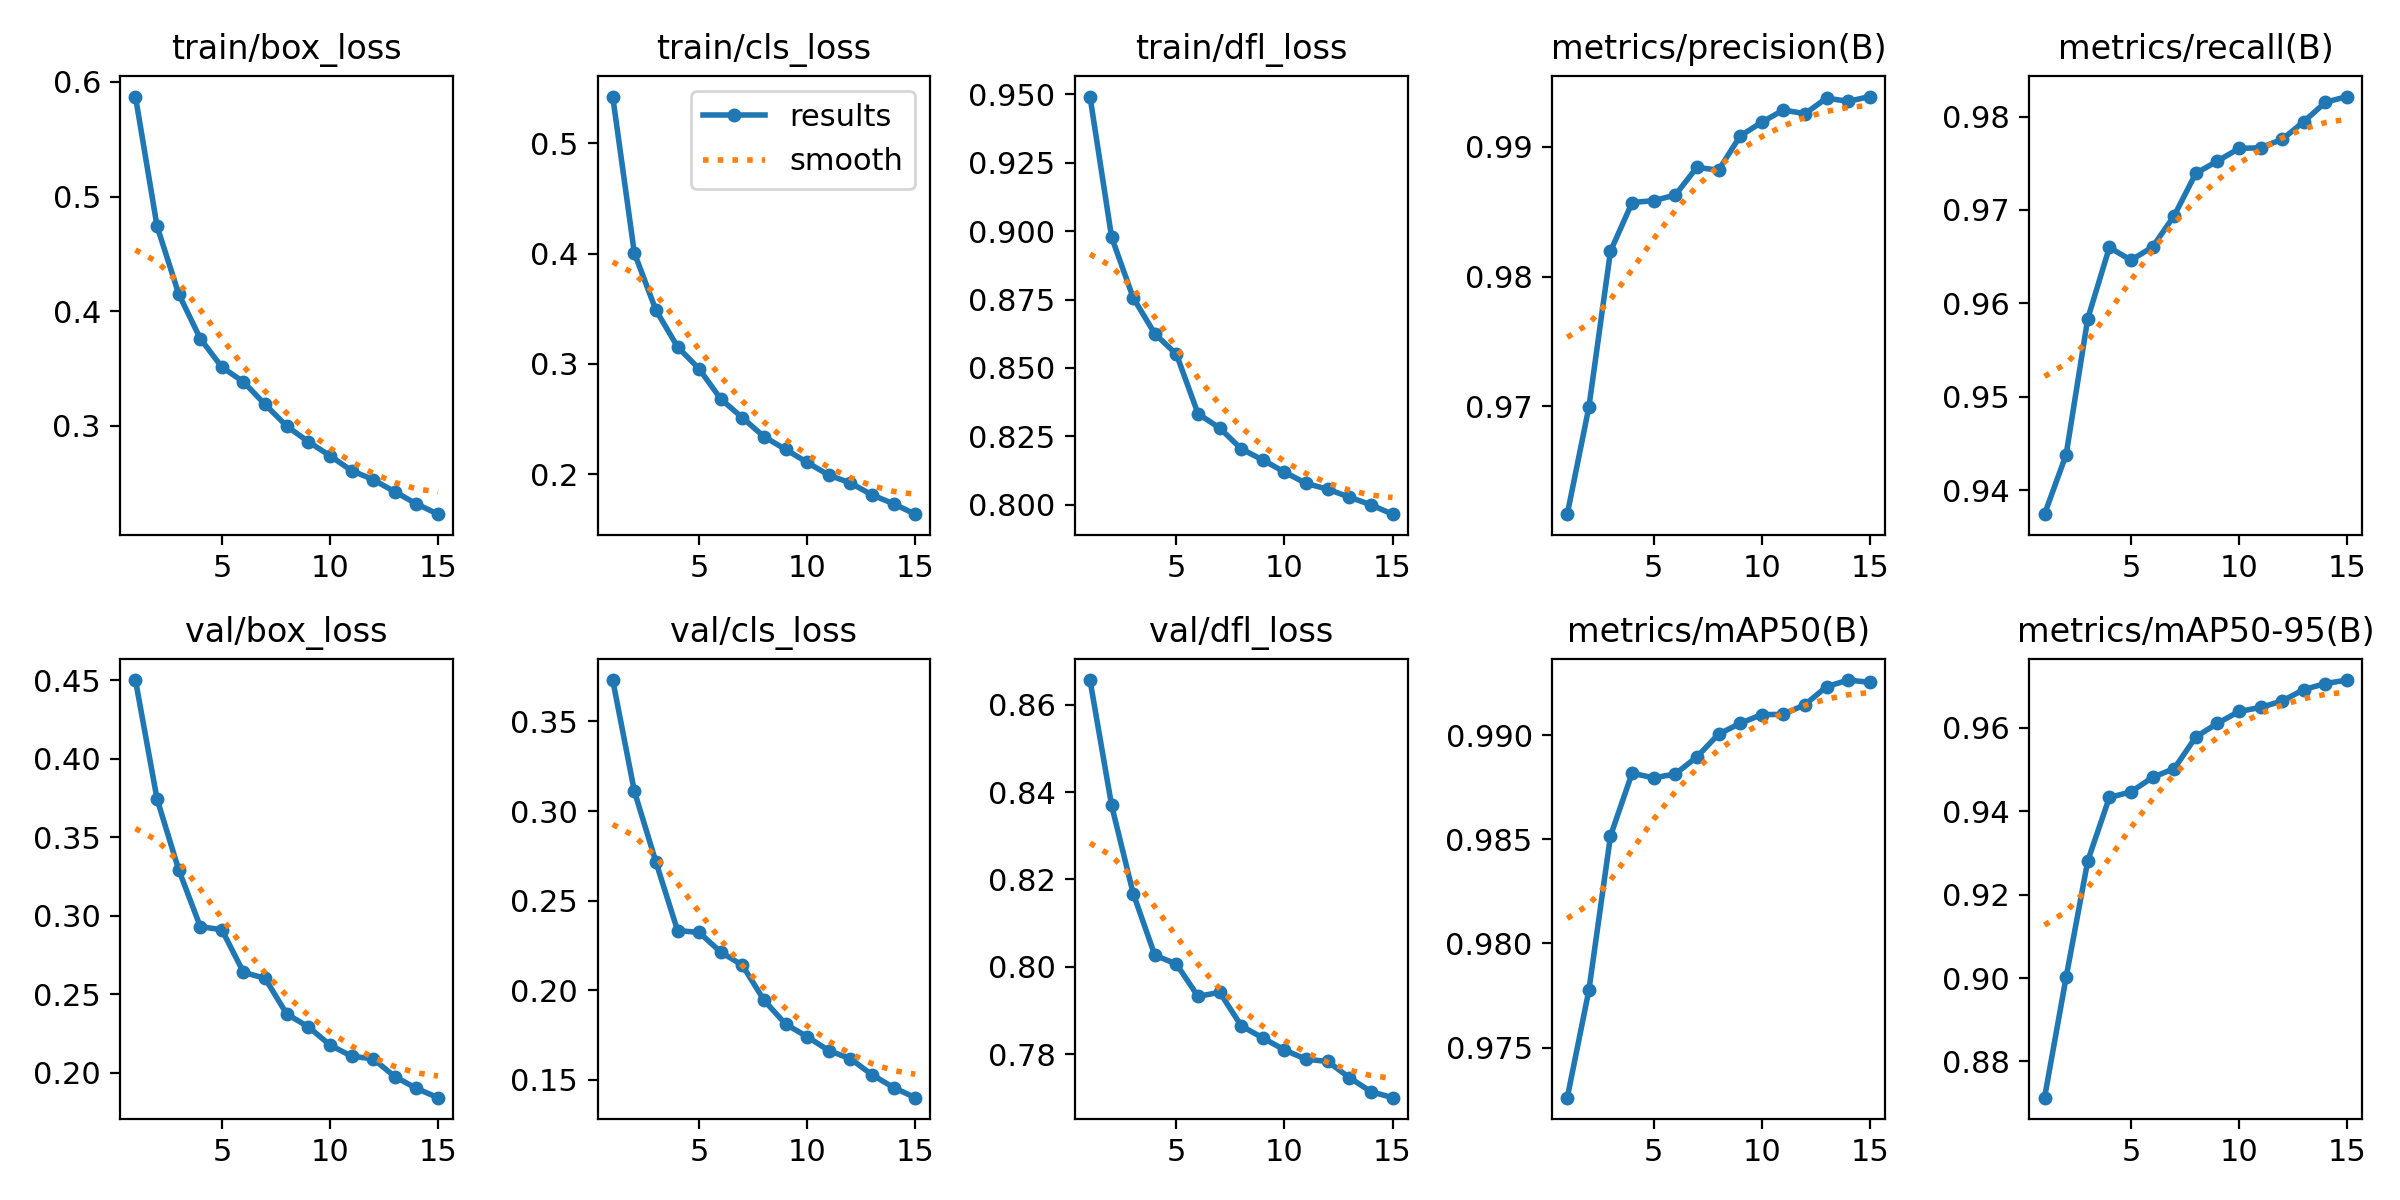

In [ ]:
Image(filename='/content/runs/detect/train/results.png', width=600)

In [ ]:
!yolo task=detect mode=val model=/content/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

Ultralytics YOLOv8.1.6 🚀 Python-3.10.12 torch-2.1.0+cu121 CUDA:0 (Tesla T4, 15102MiB)
Model summary (fused): 268 layers, 43608150 parameters, 0 gradients, 164.8 GFLOPs
val: Scanning /content/persons-1/valid/labels.cache... 2808 images, 9 backgrounds, 0 corrupt: 100% 2808/2808 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 176/176 [02:02<00:00,  1.44it/s]
                   all       2808      45181      0.994      0.982      0.993      0.973
                  head       2808      23177      0.994       0.97       0.99      0.955
                person       2808      22004      0.994      0.994      0.995      0.991
Speed: 0.3ms preprocess, 34.8ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val
